In [1]:
import os

import numpy as np
import pandas as pd
import geopandas as gpd

import matplotlib.pyplot as plt

In [2]:
_dir = '/home/jan/Documents/EPFL/project_2/data/labels/dataset_small'

dfs = []
for _file in os.listdir(_dir):
    
    if _file == 'labels.csv':
        continue
    print(_file)
    df = pd.read_csv(os.path.join(_dir, _file))
    dfs.append(df)


cocoa_1000.csv
rubber_1000.csv
mapbiomas_1000.csv


In [13]:
df = pd.concat(dfs)

In [14]:
df['geometry'] = gpd.GeoSeries.from_wkt(df['geometry'])


AttributeError: 'Series' object has no attribute 'centroid'

In [15]:
gdf = gpd.GeoDataFrame(df)
gdf['geometry'] = gdf.geometry.centroid

In [16]:
gdf = gdf.reset_index(drop=True)

In [17]:
np.unique(gdf.driver, return_counts=True)


(array(['cocoa', 'coffee', 'forest plantation', 'mining', 'palm oil',
        'pasture', 'rubber', 'soy', 'urban'], dtype=object),
 array([1000,  110, 1000, 1000, 1000, 1000, 1000, 1000, 1000]))

In [10]:
pd.DataFrame(gdf).to_csv(_dir + '/labels.csv', index=False)

In [21]:
df = pd.DataFrame(gdf)

## Data split

In [11]:
def split_by_longitude(df, split =['train', 'train', 'train', 'val']):
    # Splits dataset into train, val and test by degrees of latitude
    
    try:
        df['geometry'] = gpd.GeoSeries.from_wkt(df['geometry'])
    except TypeError: #if already a GeoSeries
        df['geometry'] = gpd.GeoSeries(df['geometry'])
    
    df['lon'] = df.geometry.apply(lambda geom: round(geom.x)) 

    for i, lon in enumerate(range(-180, 180)):
        df.loc[df['lon'] == lon, 'split'] = split[i%len(split)]
    
    df = df.drop('lon', axis=1)
    return df
    #return df.loc[df.split == 'Tr'].copy(), df.loc[df.split == 'Val'].copy(), df.loc[df.split == 'T'].copy()

In [22]:
gdf = split_by_longitude(df)

In [145]:
#gpd.GeoDataFrame(df).to_file('../data/tmp/data_split.gpkg')

['cocoa' 'coffee' 'forest plantation' 'mining' 'palm oil' 'pasture'
 'rubber' 'soy' 'urban'] [868  82 800 598 409 790 714 812 756]
['cocoa' 'coffee' 'forest plantation' 'mining' 'palm oil' 'pasture'
 'rubber' 'soy' 'urban'] [132  28 200 402 591 210 286 188 244]


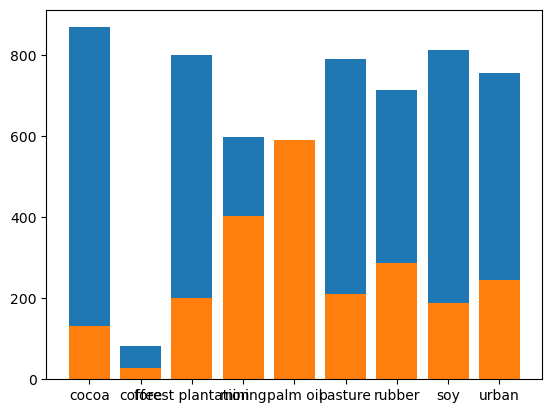

In [23]:
for dst in ['train', 'val']:
    
    classes, counts = np.unique(gdf.loc[gdf.split == dst].driver, return_counts=True)
    print(classes, counts)
    plt.bar(classes, height=counts)


In [24]:
pd.DataFrame(gdf).to_csv(_dir + '/labels.csv', index=False)

In [4]:
df = pd.read_csv(_dir + '/labels.csv')

In [5]:
df

,geometry,driver,sampleid,split
0,POINT (-6.726781621781269 5.505369307436387),cocoa,3039418,train
1,POINT (-6.113681440369697 5.477072375986622),cocoa,3040124,train
2,POINT (-2.31246031561794 5.533666238886152),cocoa,3038914,train
3,POINT (-7.066344799178449 6.109037178364705),cocoa,3026449,train
4,POINT (-5.811847504905537 6.354277250929334),cocoa,3020208,train
...,...,...,...,...
8105,POINT (-44.16598121881418 -2.4855485596303044),urban,1297786,train
8106,POINT (-60.00633229569873 -3.032622567659093),urban,1027045,train
8107,POINT (-46.8447573960586 -23.343888813606505),urban,1600833,train
8108,POINT (-59.98571678698251 -3.0609194991088575),urban,1115047,train
